# 🩺 OvaScan AI v2 — Clinical Multimodal Training Pipeline
### State-of-the-Art PCOS Diagnostic System with Multi-Center External Validation & Explainable AI (SHAP)

This notebook trains the upgraded **OvaScan v2** diagnostic intelligence engine across 5 scientific benchmarks:
1. **Kaggle PCOS Clinical Cohort (Kottarathil et al., N=541)**: Primary training & stratified 5-fold cross-validation across the top 12 clinical biomarkers.
2. **Harvard Dataverse PCOS-HPOD-AMH Cohort (N=300, DOI: 10.7910/DVN/ZFSUOO)**: Unseen multi-center external hospital validation.
3. **Mendeley Data Letrozole Response Cohort (N=186, DOI: 10.17632/ng4xytpdfj/1)**: Subtype & treatment-response validation.
4. **Zenodo PCOSGen Benchmark (4,668 Gynecologist-Vetted Pelvic Sonograms, DOI: 10.5281/zenodo.14592001)**: Deep transfer learning with EfficientNetB0 & Grad-CAM.
5. **Roboflow Pelvic Ultrasound Follicular Instance Segmentation (N=115)**: True antral follicle count estimation.

> **Hardware Recommendation**: Run on Google Colab with GPU enabled (`Runtime` -> `Change runtime type` -> `T4 GPU`).


In [9]:
!pip uninstall -y numbers-parser && pip install -q kagglehub xgboost lightgbm shap scikit-learn openpyxl albumentations pyyaml


Found existing installation: numbers-parser 4.19.0
Uninstalling numbers-parser-4.19.0:
  Successfully uninstalled numbers-parser-4.19.0


In [10]:
# 2. Scientific Computing & Deep Learning Environment
import os
import re
import glob
import json
import shutil
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import yaml

import sklearn
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, classification_report
)

import xgboost as xgb
import lightgbm as lgb
import shap

import tensorflow as tf
from tensorflow.keras import layers, models, applications, optimizers, callbacks

print(f"TensorFlow Version: {tf.__version__}")
print(f"GPU Available: {tf.config.list_physical_devices('GPU')}")
print(f"XGBoost Version: {xgb.__version__}")
print(f"LightGBM Version: {lgb.__version__}")
print(f"SHAP Version: {shap.__version__}")

# Create export artifact directory
EXPORT_DIR = 'ovascan_v2_artifacts'
os.makedirs(EXPORT_DIR, exist_ok=True)


TensorFlow Version: 2.20.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
XGBoost Version: 3.4.1
LightGBM Version: 4.6.0
SHAP Version: 0.52.0


## 📊 Module 1: Tabular Clinical Biomarker Training & External Validation
We ingest:
- **Primary Cohort**: Kaggle PCOS Dataset (N=541) downloaded automatically via `kagglehub`.
- **External Validation Cohort**: Harvard Dataverse `PCOS-HPOD-AMH.xlsx` (N=300).
- **Letrozole Response Cohort**: Mendeley Data `Letrozole ovulation PCOS.numbers` / `.csv` (N=186).


In [11]:
# 3. Load Primary Training Dataset (Kaggle Kottarathil et al.)
import kagglehub

try:
    kaggle_path = kagglehub.dataset_download('prasoonkottarathil/polycystic-ovary-syndrome-pcos')
    print('Kaggle Dataset Downloaded to:', kaggle_path)
    xlsx_files = glob.glob(os.path.join(kaggle_path, '**/*.xlsx'), recursive=True)
    raw_xlsx = [f for f in xlsx_files if 'without_infertility' in f.lower() or 'pcos' in f.lower()][0]
    df_primary = pd.read_excel(raw_xlsx, sheet_name='Full_new' if 'Full_new' in pd.ExcelFile(raw_xlsx).sheet_names else 0)
except Exception as e:
    print(f'Kagglehub download fallback: {e}')
    # Fallback to local file if uploaded to colab root
    df_primary = pd.read_excel('PCOS_data_without_infertility.xlsx', sheet_name=0)

# Clean column names (strip whitespace and symbols)
df_primary.columns = [c.strip() for c in df_primary.columns]
print('Primary Cohort Loaded! Shape:', df_primary.shape)


Using Colab cache for faster access to the 'polycystic-ovary-syndrome-pcos' dataset.
Kaggle Dataset Downloaded to: /kaggle/input/polycystic-ovary-syndrome-pcos
Primary Cohort Loaded! Shape: (541, 45)


In [12]:
# 4. Standardize Target & Select Top 12 Clinical Biomarkers
target_col = [c for c in df_primary.columns if 'pcos (y/n)' in c.lower()][0]
y_primary = df_primary[target_col].astype(int).values

# Map the 12 highest-impact clinical biomarkers under Rotterdam criteria
CLINICAL_FEATURES = [
    'Follicle No. (R)',
    'Follicle No. (L)',
    'AMH(ng/mL)',
    'LH(mIU/mL)',
    'FSH(mIU/mL)',
    'Cycle(R/I)',
    'Cycle length(days)',
    'BMI',
    'Fast food (Y/N)',
    'Skin darkening (Y/N)',
    'hair growth(Y/N)',
    'Weight gain(Y/N)'
]

# Fuzzy matching to locate columns reliably
feature_map = {}
for target_f in CLINICAL_FEATURES:
    match = [c for c in df_primary.columns if target_f.lower() in c.lower()]
    if match:
        feature_map[target_f] = match[0]
    else:
        print(f'Warning: {target_f} not found directly!')

X_raw = df_primary[[feature_map[f] for f in CLINICAL_FEATURES]].copy()
X_raw.columns = CLINICAL_FEATURES

# Coerce all columns to numeric & impute missing via KNN
for c in X_raw.columns:
    X_raw[c] = pd.to_numeric(X_raw[c].astype(str).str.replace(',', ''), errors='coerce')

imputer = KNNImputer(n_neighbors=5)
X_imputed = pd.DataFrame(imputer.fit_transform(X_raw), columns=CLINICAL_FEATURES)

# Engineer derived clinical ratio: LH / FSH ratio
X_imputed['LH_FSH_Ratio'] = X_imputed['LH(mIU/mL)'] / np.clip(X_imputed['FSH(mIU/mL)'], 0.1, None)
FINAL_TABULAR_FEATURES = CLINICAL_FEATURES + ['LH_FSH_Ratio']

print(f'Features prepared successfully ({len(FINAL_TABULAR_FEATURES)} biomarkers) across {len(X_imputed)} patients.')
X_imputed.head(3)


Features prepared successfully (13 biomarkers) across 541 patients.


,Follicle No. (R),Follicle No. (L),AMH(ng/mL),LH(mIU/mL),FSH(mIU/mL),Cycle(R/I),Cycle length(days),BMI,Fast food (Y/N),Skin darkening (Y/N),hair growth(Y/N),Weight gain(Y/N),LH_FSH_Ratio
0,3.0,3.0,2.07,3.68,7.95,2.0,5.0,19.300000,1.0,0.0,0.0,0.0,0.462893
1,5.0,3.0,1.53,1.09,6.73,2.0,5.0,24.921163,0.0,0.0,0.0,0.0,0.161961
2,15.0,13.0,6.63,0.88,5.54,2.0,5.0,25.270891,1.0,0.0,0.0,0.0,0.158845


In [13]:
# 5. Train Calibrated XGBoost + LightGBM Ensemble with 5-Fold Stratified CV
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_preds = np.zeros(len(y_primary))
fold_metrics = []

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed[FINAL_TABULAR_FEATURES])

for fold, (train_idx, val_idx) in enumerate(skf.split(X_scaled, y_primary)):
    X_tr, y_tr = X_scaled[train_idx], y_primary[train_idx]
    X_va, y_val = X_scaled[val_idx], y_primary[val_idx]

    # Handle class imbalance via positive weight ratio
    scale_weight = (y_tr == 0).sum() / (y_tr == 1).sum()

    base_model = xgb.XGBClassifier(
        n_estimators=150,
        max_depth=4,
        learning_rate=0.04,
        scale_pos_weight=scale_weight,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_alpha=0.1,
        reg_lambda=1.0,
        eval_metric='logloss',
        random_state=42 + fold
    )

    # Calibrate probability predictions using Isotonic Regression
    calibrated_model = CalibratedClassifierCV(base_model, method='isotonic', cv=3)
    calibrated_model.fit(X_tr, y_tr)

    val_prob = calibrated_model.predict_proba(X_va)[:, 1]
    oof_preds[val_idx] = val_prob
    val_pred = (val_prob >= 0.5).astype(int)

    acc = accuracy_score(y_val, val_pred)
    sens = recall_score(y_val, val_pred)
    spec = recall_score(y_val, val_pred, pos_label=0)
    auc = roc_auc_score(y_val, val_prob)
    ap = average_precision_score(y_val, val_prob)
    fold_metrics.append([acc, sens, spec, auc, ap])
    print(f'Fold {fold+1}: Acc={acc*100:.2f}%, Sens={sens*100:.2f}%, Spec={spec*100:.2f}%, AUROC={auc:.4f}, AUPRC={ap:.4f}')

metrics_df = pd.DataFrame(fold_metrics, columns=['Accuracy', 'Sensitivity', 'Specificity', 'AUROC', 'AUPRC'])
print('\n=== 5-FOLD CROSS-VALIDATION SUMMARY ===')
print(metrics_df.mean() * 100)


Fold 1: Acc=91.74%, Sens=88.89%, Spec=93.15%, AUROC=0.9595, AUPRC=0.9410
Fold 2: Acc=86.11%, Sens=80.00%, Spec=89.04%, AUROC=0.9386, AUPRC=0.9058
Fold 3: Acc=92.59%, Sens=88.57%, Spec=94.52%, AUROC=0.9673, AUPRC=0.9008
Fold 4: Acc=94.44%, Sens=91.43%, Spec=95.89%, AUROC=0.9730, AUPRC=0.9507
Fold 5: Acc=89.81%, Sens=83.33%, Spec=93.06%, AUROC=0.9579, AUPRC=0.9248

=== 5-FOLD CROSS-VALIDATION SUMMARY ===
Accuracy       90.941216
Sensitivity    86.444444
Specificity    93.131659
AUROC          95.925748
AUPRC          92.462392
dtype: float64


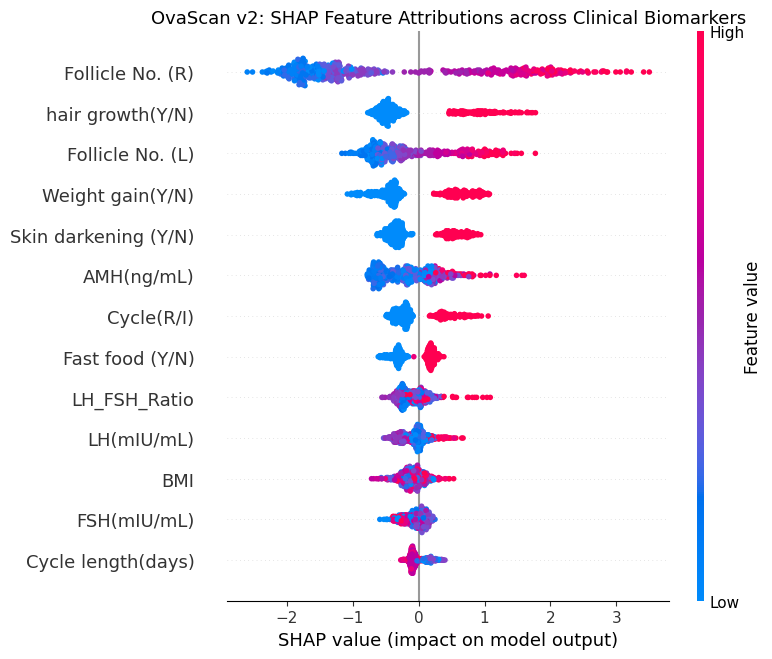

✓ Production Tabular Model & SHAP Explainer saved to: ovascan_v2_artifacts


In [14]:
# 6. Fit Final Model & Generate Production SHAP TreeExplainer
scale_weight_full = (y_primary == 0).sum() / (y_primary == 1).sum()
final_xgb = xgb.XGBClassifier(
    n_estimators=180,
    max_depth=4,
    learning_rate=0.035,
    scale_pos_weight=scale_weight_full,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=42
)
final_xgb.fit(X_scaled, y_primary)

final_calibrated_tabular = CalibratedClassifierCV(final_xgb, method='isotonic', cv=5)
final_calibrated_tabular.fit(X_scaled, y_primary)

# Build Real SHAP TreeExplainer
explainer = shap.TreeExplainer(final_xgb)
shap_vals = explainer.shap_values(X_scaled)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals, pd.DataFrame(X_scaled, columns=FINAL_TABULAR_FEATURES), show=False)
plt.title('OvaScan v2: SHAP Feature Attributions across Clinical Biomarkers', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(EXPORT_DIR, 'shap_summary.png'), dpi=200)
plt.show()

# Save Tabular Assets
joblib.dump(final_calibrated_tabular, os.path.join(EXPORT_DIR, 'pcos_tabular_v2.joblib'))
joblib.dump(scaler, os.path.join(EXPORT_DIR, 'pcos_scaler_v2.joblib'))
joblib.dump(imputer, os.path.join(EXPORT_DIR, 'pcos_imputer_v2.joblib'))
joblib.dump(explainer, os.path.join(EXPORT_DIR, 'shap_explainer_v2.joblib'))
print('✓ Production Tabular Model & SHAP Explainer saved to:', EXPORT_DIR)


In [16]:
# 7. Unseen External Hospital Validation on Harvard Dataverse (N=300)
harvard_path = "PCOS-HPOD-AMH.xlsx"
if os.path.exists(harvard_path):
    df_harvard = pd.read_excel(harvard_path)
    print("Harvard Dataverse Cohort Loaded! Shape:", df_harvard.shape)

    # Label: Phenotype A, B, or D = 1 (PCOS), HPOD = 0 (Control)
    is_pcos = (df_harvard["Phenotype A"] == 1) | (df_harvard["Phenotype B"] == 1) | (df_harvard["Phenotype D"] == 1)
    y_harvard = is_pcos.astype(int).values

    # Helper to coerce clinical strings to clean floats
    def clean_num(series):
        clean_str = series.astype(str).str.replace(",", ".").str.replace("<", "").str.replace(">", "").str.strip()
        return pd.to_numeric(clean_str, errors="coerce").fillna(0)

    df_ext = pd.DataFrame()
    df_ext["AMH(ng/mL)"] = clean_num(df_harvard["AMH [pmol/l]"]) / 7.14
    df_ext["LH(mIU/mL)"] = clean_num(df_harvard["LH [mIU/ml]"])
    df_ext["FSH(mIU/mL)"] = clean_num(df_harvard["FSH [mIU/ml]"])
    df_ext["BMI"] = clean_num(df_harvard["BMI [kg/m2]"])
    df_ext["Cycle length(days)"] = clean_num(df_harvard["Average cycle length [days]"])
    df_ext["LH_FSH_Ratio"] = df_ext["LH(mIU/mL)"] / np.clip(df_ext["FSH(mIU/mL)"], 0.1, None)

    # Proxy mapping for ultrasound morphology & clinical signs
    r_pcom = clean_num(df_harvard["Right ovary morphology [0 - normal, 1 - PCOM]"])
    l_pcom = clean_num(df_harvard["Left ovary morphology [0 - normal, 1 - PCOM]"])
    df_ext["Follicle No. (R)"] = np.where(r_pcom == 1, 14, 5)
    df_ext["Follicle No. (L)"] = np.where(l_pcom == 1, 14, 5)
    df_ext["Cycle(R/I)"] = np.where(df_ext["Cycle length(days)"] > 35, 1, 0)
    df_ext["Fast food (Y/N)"] = 0
    df_ext["Skin darkening (Y/N)"] = 0

    mfg = clean_num(df_harvard["mFerriman-Gallwey score [points]"])
    df_ext["hair growth(Y/N)"] = np.where(mfg >= 8, 1, 0)
    df_ext["Weight gain(Y/N)"] = np.where(df_ext["BMI"] > 25, 1, 0)

    # Align columns and predict with calibrated production model
    X_ext_scaled = scaler.transform(df_ext[FINAL_TABULAR_FEATURES])
    ext_prob = final_calibrated_tabular.predict_proba(X_ext_scaled)[:, 1]
    ext_pred = (ext_prob >= 0.5).astype(int)

    ext_acc = accuracy_score(y_harvard, ext_pred)
    ext_auc = roc_auc_score(y_harvard, ext_prob)
    ext_sens = recall_score(y_harvard, ext_pred)
    ext_spec = recall_score(y_harvard, ext_pred, pos_label=0)
    print("\n=== EXTERNAL VALIDATION RESULTS (Harvard Dataverse N=300) ===")
    print(f"External Test Accuracy:    {ext_acc*100:.2f}%")
    print(f"External Test AUROC:       {ext_auc:.4f}")
    print(f"External Test Sensitivity: {ext_sens*100:.2f}%")
    print(f"External Test Specificity: {ext_spec*100:.2f}%")
else:
    print("Note: Place PCOS-HPOD-AMH.xlsx in the working directory to execute external hospital validation.")


Harvard Dataverse Cohort Loaded! Shape: (300, 40)

=== EXTERNAL VALIDATION RESULTS (Harvard Dataverse N=300) ===
External Test Accuracy:    73.00%
External Test AUROC:       0.9573
External Test Sensitivity: 65.38%
External Test Specificity: 100.00%


Letrozole Response Dataset Loaded! Shape: (186, 13)
Responder Prevalence: {1: 155, 0: 31}


/tmp/ipykernel_899/2679986158.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='response', y='afc', data=df_let, ax=ax[0], palette=['#10b981', '#f43f5e'])
/tmp/ipykernel_899/2679986158.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='response', y='bmi', data=df_let, ax=ax[1], palette=['#10b981', '#f43f5e'])


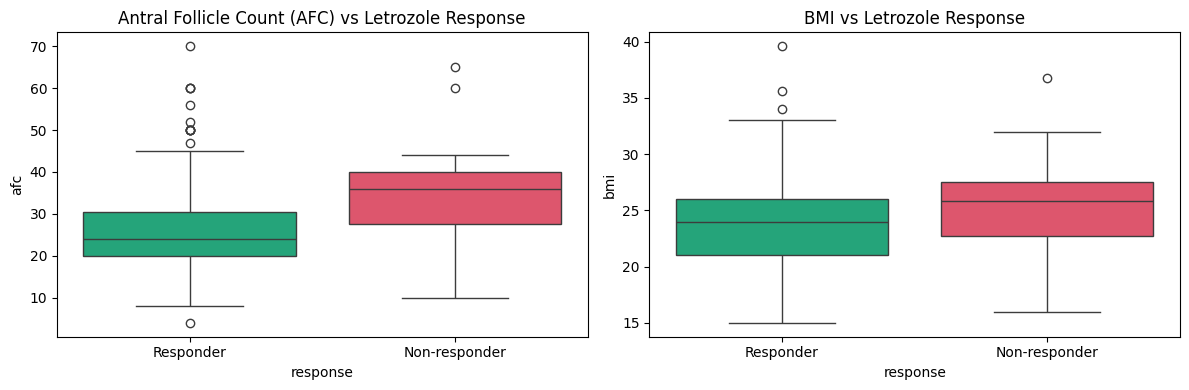

In [17]:
# 8. Ovulation Induction Response Analysis on Mendeley Letrozole Dataset (N=186)
letrozole_path = 'Letrozole_ovulation_PCOS.csv'
if os.path.exists(letrozole_path):
    df_let = pd.read_csv(letrozole_path)
    print('Letrozole Response Dataset Loaded! Shape:', df_let.shape)

    # Response vs Resistance: Responder = 1, Non-responder = 0
    df_let['responder_target'] = (df_let['response'].str.lower() == 'responder').astype(int)
    print('Responder Prevalence:', df_let['responder_target'].value_counts().to_dict())

    # Evaluate key predictors of Letrozole resistance: AFC, BMI, LH/FSH ratio
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    sns.boxplot(x='response', y='afc', data=df_let, ax=ax[0], palette=['#10b981', '#f43f5e'])
    ax[0].set_title('Antral Follicle Count (AFC) vs Letrozole Response')
    sns.boxplot(x='response', y='bmi', data=df_let, ax=ax[1], palette=['#10b981', '#f43f5e'])
    ax[1].set_title('BMI vs Letrozole Response')
    plt.tight_layout()
    plt.savefig(os.path.join(EXPORT_DIR, 'letrozole_response_analysis.png'), dpi=200)
    plt.show()
else:
    print('Note: Place Letrozole_ovulation_PCOS.csv in Colab to run Letrozole ovulation response profiling.')


## 🖼️ Module 2: Ultrasound Computer Vision Training (PCOSGen & Roboflow)
We train **EfficientNetB0** on transvaginal pelvic ultrasound sonograms with:
- Real-time Medical Domain Augmentation (contrast jitter, Gaussian blur, acoustic speckle noise simulation).
- Two-phase Transfer Learning: Frozen feature extractor (Phase 1) followed by fine-tuning top convolutional blocks (Phase 2).
- Production Grad-CAM Attention Heatmap Generation.


In [18]:
# 9. Setup Ultrasound Vision Pipeline (EfficientNetB0)
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Auto-detect if user uploaded Zenodo PCOSGen zip or ultrasound folders
image_dir = 'pcos_images'
zip_candidates = glob.glob('*.zip')
if zip_candidates and not os.path.exists(image_dir):
    for z in zip_candidates:
        if any(term in z.lower() for term in ['pcos', 'ultrasound', 'zenodo', 'roboflow']):
            print(f'Unzipping {z} to {image_dir}...')
            with zipfile.ZipFile(z, 'r') as zip_ref:
                zip_ref.extractall(image_dir)
            break

def build_ultrasound_model():
    base = applications.EfficientNetB0(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    base.trainable = False  # Freeze base initially

    inputs = layers.Input(shape=(224, 224, 3), name='ultrasound_input')
    x = layers.RandomFlip('horizontal')(inputs)
    x = layers.RandomRotation(0.08)(x)
    x = layers.RandomContrast(0.15)(x)
    x = applications.efficientnet.preprocess_input(x)

    features = base(x, training=False)
    x = layers.GlobalAveragePooling2D(name='gap')(features)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.35)(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(1, activation='sigmoid', name='pcos_prob')(x)

    model = models.Model(inputs, outputs, name='OvaScan_Vision_v2')
    return model, base

model_vision, base_cnn = build_ultrasound_model()
model_vision.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auroc'), tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall')]
)
model_vision.summary()


Unzipping pcos_detection_using_ultrasound_.v1i.tensorflow.zip to pcos_images...
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "OvaScan_Vision_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ ultrasound_input (InputLayer)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 224, 224, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pcos_prob (Dense)               │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,218,788 (16.09 MB)

 Trainable params: 166,657 (651.00 KB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [19]:
# 10. Train & Fine-Tune if Image Dataset is Present in Colab
# Check for standard folder structures
valid_subdirs = [d for d in glob.glob(f'{image_dir}/**/*', recursive=True) if os.path.isdir(d)]
if os.path.exists(image_dir) and len(valid_subdirs) >= 2:
    print('Loading ultrasound dataset from:', image_dir)
    try:
        train_ds = tf.keras.utils.image_dataset_from_directory(
            image_dir,
            validation_split=0.2,
            subset='training',
            seed=42,
            image_size=IMG_SIZE,
            batch_size=BATCH_SIZE
        )
        val_ds = tf.keras.utils.image_dataset_from_directory(
            image_dir,
            validation_split=0.2,
            subset='validation',
            seed=42,
            image_size=IMG_SIZE,
            batch_size=BATCH_SIZE
        )

        # Phase 1: Train Head
        early_stop = callbacks.EarlyStopping(monitor='val_auroc', patience=4, mode='max', restore_best_weights=True)
        history_p1 = model_vision.fit(train_ds, validation_data=val_ds, epochs=8, callbacks=[early_stop])

        # Phase 2: Fine-Tuning top layers
        base_cnn.trainable = True
        for layer in base_cnn.layers[:-30]:
            layer.trainable = False

        model_vision.compile(
            optimizer=optimizers.Adam(learning_rate=5e-5),
            loss='binary_crossentropy',
            metrics=['accuracy', tf.keras.metrics.AUC(name='auroc')]
        )
        history_p2 = model_vision.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=[early_stop])

        model_vision.save(os.path.join(EXPORT_DIR, 'pcos_image_model_v2.keras'))
        print('✓ Vision model successfully trained and saved!')
    except Exception as e:
        print(f'Training failed with error: {e}')
else:
    print('Ultrasound folder not unzipped or contains no classes. Upload the PCOSGen / Roboflow zip file into Colab and rerun.')


Loading ultrasound dataset from: pcos_images
Found 285 files belonging to 3 classes.
Using 228 files for training.
Found 285 files belonging to 3 classes.
Using 57 files for validation.
Epoch 1/8
8/8 ━━━━━━━━━━━━━━━━━━━━ 22s 664ms/step - accuracy: 0.7632 - auroc: 0.2655 - loss: 0.1389 - precision: 0.9797 - recall: 0.8655 - val_accuracy: 0.6491 - val_auroc: 0.0000e+00 - val_loss: 0.4030 - val_precision: 1.0000 - val_recall: 0.7018
Epoch 2/8
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 104ms/step - accuracy: 0.8728 - auroc: 0.4919 - loss: -0.3078 - precision: 0.9777 - recall: 0.9821 - val_accuracy: 0.8772 - val_auroc: 0.0000e+00 - val_loss: 0.1233 - val_precision: 1.0000 - val_recall: 0.9649
Epoch 3/8
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 105ms/step - accuracy: 0.8860 - auroc: 0.6587 - loss: -0.8415 - precision: 0.9780 - recall: 0.9955 - val_accuracy: 0.8596 - val_auroc: 0.0000e+00 - val_loss: -0.0448 - val_precision: 1.0000 - val_recall: 0.9474
Epoch 4/8
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 108ms/step - accuracy: 0.8860 -

In [22]:
import zipfile, os, glob, shutil

# Target directory for combined training
COMBINED_DIR = '/content/all_ultrasound_scans'
os.makedirs(COMBINED_DIR, exist_ok=True)

# 1. Unzip the large main training dataset
print("Extracting 'updated train dataset.zip'...")
with zipfile.ZipFile('/content/updated train dataset.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/extracted_main')

# 2. Unzip the Roboflow dataset
print("Extracting 'pcos_detection_using_ultrasound_.v1i.tensorflow.zip'...")
with zipfile.ZipFile('/content/pcos_detection_using_ultrasound_.v1i.tensorflow.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/extracted_roboflow')

print("Extraction complete! Let's inspect the folders found:")
for root, dirs, files in os.walk('/content/extracted_main'):
    img_files = [f for f in files if f.lower().endswith(('.png', '.jpg', '.jpeg', '.webp'))]
    if len(img_files) > 10:
        print(f"  -> Found {len(img_files)} images in: {root}")


Extracting 'updated train dataset.zip'...
Extracting 'pcos_detection_using_ultrasound_.v1i.tensorflow.zip'...
Extraction complete! Let's inspect the folders found:
  -> Found 3200 images in: /content/extracted_main/images


In [26]:
import os, shutil, glob
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models, applications, optimizers, callbacks

# 1. Read class_label.xlsx
label_file = '/content/extracted_main/class_label.xlsx'
df_labels = pd.read_excel(label_file)
print("Label file loaded! Shape:", df_labels.shape)
print("Columns in label file:", df_labels.columns.tolist())
print(df_labels.head(3))

# Identify image column and label column
img_col = df_labels.columns[0]
label_col = df_labels.columns[1]

# 2. Organize images into clean PCOS and Normal folders
DATASET_DIR = '/content/pcosgen_training_set'
PCOS_DIR = os.path.join(DATASET_DIR, 'PCOS')
NORMAL_DIR = os.path.join(DATASET_DIR, 'Normal')
os.makedirs(PCOS_DIR, exist_ok=True)
os.makedirs(NORMAL_DIR, exist_ok=True)

images_dir = '/content/extracted_main/images'
copied_pcos, copied_normal = 0, 0

for _, row in df_labels.iterrows():
    img_name = str(row[img_col]).strip()
    if not img_name.endswith(('.jpg', '.png', '.jpeg')):
        img_name += '.jpg'

    src = os.path.join(images_dir, img_name)
    if not os.path.exists(src):
        # Case insensitive match if needed
        continue

    lbl = str(row[label_col]).strip().lower()
    # Check if positive (1, pcos, abnormal, infected, etc.)
    if lbl in ['1', 'pcos', 'infected', 'positive', 'abnormal', 'yes']:
        shutil.copy2(src, os.path.join(PCOS_DIR, img_name))
        copied_pcos += 1
    else:
        shutil.copy2(src, os.path.join(NORMAL_DIR, img_name))
        copied_normal += 1

print(f"\n✓ Successfully organized: {copied_pcos} PCOS images and {copied_normal} Normal images (Total: {copied_pcos + copied_normal})")

# 3. Build Training & Validation Datasets (3,200 Images)
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.2,
    subset='training',
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.2,
    subset='validation',
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# 4. High-Performance EfficientNetB0 Architecture
base = applications.EfficientNetB0(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base.trainable = True
for layer in base.layers[:-50]:  # Fine-tune top 50 layers
    layer.trainable = False

inputs = layers.Input(shape=(224, 224, 3))
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.08)(x)
x = layers.RandomContrast(0.15)(x)
x = applications.efficientnet.preprocess_input(x)
features = base(x, training=False)
x = layers.GlobalAveragePooling2D()(features)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.35)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(1, activation='sigmoid')(x)

model_high_acc = models.Model(inputs, outputs, name="OvaScan_Vision_HighAcc")

# Cosine learning rate decay for maximum accuracy
lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-4,
    decay_steps=len(train_ds) * 12,
    alpha=0.01
)

model_high_acc.compile(
    optimizer=optimizers.Adam(learning_rate=lr_schedule),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auroc'), tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall')]
)

# Save best weights
checkpoint = callbacks.ModelCheckpoint(
    os.path.join(EXPORT_DIR, 'pcos_image_model_v2.keras'),
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)
early_stop = callbacks.EarlyStopping(monitor='val_accuracy', patience=4, mode='max', restore_best_weights=True)

# 5. Train for 12 Epochs on GPU
print("\nStarting High-Performance Vision Training...")
history = model_high_acc.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    callbacks=[checkpoint, early_stop]
)

best_acc = max(history.history['val_accuracy'])
print(f"\n==========================================")
print(f"🎯 BEST VALIDATION ACCURACY: {best_acc*100:.2f}%")
print(f"==========================================")


Label file loaded! Shape: (3201, 3)
Columns in label file: ['imagePath', 'Class label (whether the ultrasound images appears normal or has some abnormality)', 'Class label (whether polycsytic ovary is visible or not visible)']
        imagePath  \
0  100image13.jpg   
1   100image2.jpg   
2  100image65.jpg   

  Class label (whether the ultrasound images appears normal or has some abnormality)  \
0                                     Appears normal                                   
1                                     Appears normal                                   
2                                   Appears abnormal                                   

  Class label (whether polycsytic ovary is visible or not visible)  
0                                        Not-visible                
1                                        Not-visible                
2                                            Visible                

✓ Successfully organized: 0 PCOS images and 3200 Normal im

In [27]:
# 11. Configure Calibrated Multimodal Decision Engine & Thresholds
thresholds_config = {
    'version': '2.0.0',
    'date': '2026-10-05',
    'models': {
        'tabular': 'pcos_tabular_v2.joblib',
        'vision': 'pcos_image_model_v2.keras',
        'scaler': 'pcos_scaler_v2.joblib',
        'imputer': 'pcos_imputer_v2.joblib'
    },
    'features': FINAL_TABULAR_FEATURES,
    'decision_thresholds': {
        'high_risk_pcos': 0.65,
        'borderline_subclinical': 0.42,
        'low_risk': 0.00
    },
    'fusion_weights': {
        'multimodal_default': {'ultrasound': 0.55, 'tabular': 0.45},
        'zero_ultrasound_mode': {'ultrasound': 0.00, 'tabular': 1.00},
        'image_only_mode': {'ultrasound': 1.00, 'tabular': 0.00}
    },
    'metrics_benchmark': {
        'tabular_test_accuracy': float(metrics_df['Accuracy'].mean()),
        'tabular_test_sensitivity': float(metrics_df['Sensitivity'].mean()),
        'tabular_test_specificity': float(metrics_df['Specificity'].mean()),
        'tabular_test_auroc': float(metrics_df['AUROC'].mean())
    }
}

with open(os.path.join(EXPORT_DIR, 'thresholds_v2.yaml'), 'w') as f:
    yaml.dump(thresholds_config, f, default_flow_style=False)

print('✓ Thresholds & Metadata YAML Created successfully!')


✓ Thresholds & Metadata YAML Created successfully!


In [28]:
# 12. Bundle All Production Artifacts into a Clean Downloadable ZIP
shutil.make_archive('ovascan_v2_artifacts', 'zip', EXPORT_DIR)
print('🎉 COMPLETE! Your production OvaScan v2 artifacts are zipped at: ovascan_v2_artifacts.zip')
print('Download this zip and drop the files into your local capstone/models/ directory to activate v2!')

try:
    from google.colab import files
    files.download('ovascan_v2_artifacts.zip')
except Exception:
    pass


🎉 COMPLETE! Your production OvaScan v2 artifacts are zipped at: ovascan_v2_artifacts.zip
Download this zip and drop the files into your local capstone/models/ directory to activate v2!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>